# 05. Машинне навчання: Прогнозування стартів у [T, T+1h), перевірка на двох джерелах та Walk-Forward

Цей блокнот підсумовує результати моделювання на двох незалежних джерелах даних:
1. **Official (`official_data_uk.csv` -> `ml_features_hourly.parquet`):** `797,428` спокійних область-годин (`is_active_T == 0`, `0` дублікатів; у повному Test `2025-06-01 — 2026-09-07` — `197,083` спокійні область-години з `266,904` загальних).
2. **Volunteer (`volunteer_data_uk.csv` -> `volunteer_ml_features_hourly_*.parquet`):** друге незалежне джерело (`871,505` спокійних область-годин для варіанта `(а) naive_as_is` та `870,938` для каузального `(в) naive_fixed_D`; у повному Test `naive_fixed_D` — `256,490` спокійних область-годин).

### Заздалегідь зафіксоване правило вибору моделі (Pre-Specified Selection Rule):
- Кандидат серед заздалегідь визначених моделей (`Baselines 1–3`, `LogReg A/B/C`, `LightGBM A/B/C`) обирається **виключно за найвищим `PR-AUC` на Validation (`2024-05-01 — 2025-05-31`)**.
- За цим правилом на Validation обох джерел обрано **`LightGBM (Set C: Spatial + Adaptive)`** (`Val PR-AUC = 0.3012 [0.289, 0.314]` на Official та `0.3107 [0.299, 0.323]` на Volunteer `naive_as_is` / `0.3116` на `naive_fixed_D`).
- **Важливе застереження щодо Volunteer:** на тестовій вибірці Volunteer навіть після Walk-Forward перенавчання `LightGBM (Set C)` не є безумовно найкращим за всіма метриками — за об'єднаним `PR-AUC` він дещо поступається `LogReg (Set C) [Static Initial Train]` (`0.4050` проти `0.4097`, $\Delta = -0.0046 \ [-0.0081, -0.0013]$) та `LogReg [WF Expanding]` (`0.4100`), переважаючи `LogReg` лише за $F_2$-мірою (`0.5989` проти `0.5924`, $\Delta = +0.0064 \ [+0.0044, +0.0083]$) та калібруванням `Brier Score` (`0.1093` проти `0.2645`).
- Експерименти `Set B` (як пост-хок лідер серед статичних моделей на Test Official), `Set C'` (19 ознак без найбільш нестаціонарних) та `Set D` (+відносні частки у Walk-Forward) явно позначені як **пост-хок (`post-hoc`)**.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

off_dir = Path("../reports/official")
vol_dir = Path("../reports/volunteer")
comp_dir = Path("../reports/comparison")

val_off = pd.read_csv(off_dir / "ml_validation_benchmark.csv")
test_off = pd.read_csv(off_dir / "ml_models_benchmark.csv")
pre_off = pd.read_csv(off_dir / "ml_test_pre_aug2025_benchmark.csv")
post_off = pd.read_csv(off_dir / "ml_test_post_aug2025_benchmark.csv")
rec_off = pd.read_csv(off_dir / "ml_recent_60d_benchmark.csv")

val_vol = pd.read_csv(vol_dir / "volunteer_ml_validation_benchmark.csv")
test_vol = pd.read_csv(vol_dir / "volunteer_ml_models_benchmark.csv")
rec_vol = pd.read_csv(vol_dir / "volunteer_ml_recent_60d_benchmark.csv")
sens_vol = pd.read_csv(vol_dir / "volunteer_naive_sensitivity.csv")

wf_off_full = pd.read_csv(off_dir / "walk_forward_overall_benchmark.csv")
wf_off_rec = pd.read_csv(off_dir / "walk_forward_recent_60d_benchmark.csv")
wf_off_m = pd.read_csv(off_dir / "walk_forward_monthly_metrics.csv")

wf_vol_full = pd.read_csv(vol_dir / "volunteer_walk_forward_overall_benchmark.csv")
wf_vol_rec = pd.read_csv(vol_dir / "volunteer_walk_forward_recent_60d_benchmark.csv")
wf_vol_m = pd.read_csv(vol_dir / "volunteer_walk_forward_monthly_metrics.csv")

## 1. Вибір моделі на Validation (2024-05 — 2025-05, Day-Block Bootstrap N=500)

In [2]:
cols_val = ["model", "threshold", "pr_auc", "pr_auc_ci_95", "f2_score", "f2_ci_95", "prec_at_adapt_recall", "selection_status"]
print("=== OFFICIAL: Validation (2024-05 — 2025-05) ===")
display(val_off[cols_val])
print("\n=== VOLUNTEER (naive_as_is): Validation (2024-05 — 2025-05) ===")
display(val_vol[cols_val])

=== OFFICIAL: Validation (2024-05 — 2025-05) ===


,model,threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.087718,"[0.079, 0.096]",NaN,pre-specified candidate
1,Baseline 2: Historical Lookup Table,0.085235,0.194529,"[0.187, 0.202]",0.476754,"[0.468, 0.486]",0.191132,pre-specified candidate
2,Baseline 3: Adaptive 14-day Rolling,0.089195,0.250806,"[0.242, 0.260]",0.488594,"[0.481, 0.497]",0.200804,pre-specified candidate
3,LogReg (Set A: No Spatial),0.517586,0.266656,"[0.258, 0.277]",0.481590,"[0.473, 0.491]",0.193481,pre-specified candidate
4,LogReg (Set B: With Spatial),0.561207,0.288191,"[0.280, 0.297]",0.504894,"[0.497, 0.513]",0.214795,pre-specified candidate
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.270086,"[0.262, 0.278]",0.522130,"[0.515, 0.529]",0.231052,pre-specified candidate
6,LogReg (Set C': Adaptive + Lags),0.541379,0.288399,"[0.280, 0.297]",0.516882,"[0.510, 0.524]",0.225190,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.093276,0.268010,"[0.259, 0.278]",0.487744,"[0.480, 0.496]",0.199302,pre-specified candidate
8,LightGBM (Set B: With Spatial),0.109138,0.296142,"[0.287, 0.306]",0.524065,"[0.516, 0.531]",0.231350,pre-specified candidate
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.301225,"[0.292, 0.311]",0.533069,"[0.526, 0.540]",0.241161,pre-specified winner (selected on Val by PR-AUC)



=== VOLUNTEER (naive_as_is): Validation (2024-05 — 2025-05) ===


,model,threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.099301,"[0.093, 0.107]",NaN,pre-specified candidate
1,Baseline 2: Historical Lookup Table,0.077414,0.232132,"[0.225, 0.239]",0.496578,"[0.489, 0.504]",0.191065,pre-specified candidate
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.266573,"[0.260, 0.273]",0.514699,"[0.508, 0.522]",0.209591,pre-specified candidate
3,LogReg (Set A: No Spatial),0.497759,0.240071,"[0.233, 0.247]",0.503941,"[0.498, 0.510]",0.195246,pre-specified candidate
4,LogReg (Set B: With Spatial),0.473966,0.275864,"[0.269, 0.282]",0.520021,"[0.514, 0.527]",0.213623,pre-specified candidate
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.293944,"[0.287, 0.300]",0.523633,"[0.517, 0.530]",0.215923,pre-specified candidate
6,LogReg (Set C': Adaptive + Lags),0.477931,0.298219,"[0.291, 0.305]",0.524167,"[0.518, 0.531]",0.217285,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.081379,0.250185,"[0.243, 0.258]",0.499816,"[0.493, 0.507]",0.193327,pre-specified candidate
8,LightGBM (Set B: With Spatial),0.097241,0.283634,"[0.276, 0.290]",0.525173,"[0.518, 0.531]",0.218322,pre-specified candidate
9,LightGBM (Set C: Spatial + Adaptive),0.117069,0.310667,"[0.303, 0.318]",0.532077,"[0.525, 0.539]",0.224273,pre-specified winner (selected on Val by PR-AUC)


## 2. Статичне навчання (2022–2024): Повний Test та Останні 60 днів на обох джерелах

In [3]:
cols_test = ["model", "frozen_threshold", "pr_auc", "pr_auc_ci_95", "f2_score", "f2_ci_95", "prec_at_adapt_recall", "selection_status"]
print("=== OFFICIAL: Повний Test (2025-06 — 2026-09) ===")
display(test_off[cols_test])
print("\n=== OFFICIAL: Останні 60 днів (2026-07-09 — 2026-09-07) ===")
display(rec_off[cols_test[:-1]])
print("\n=== VOLUNTEER (naive_as_is): Повний Test (2025-06 — 2026-10) ===")
display(test_vol[cols_test])
print("\n=== VOLUNTEER (naive_as_is): Останні 60 днів (2026-08-12 — 2026-10-11) ===")
display(rec_vol[cols_test[:-1]])

=== OFFICIAL: Повний Test (2025-06 — 2026-09) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.103384,"[0.096, 0.111]",NaN,pre-specified candidate
1,Baseline 2: Historical Lookup Table,0.085235,0.220406,"[0.212, 0.228]",0.503292,"[0.495, 0.511]",0.211073,pre-specified candidate
2,Baseline 3: Adaptive 14-day Rolling,0.089195,0.303127,"[0.292, 0.315]",0.529945,"[0.520, 0.538]",0.231394,pre-specified candidate
3,LogReg (Set A: No Spatial),0.517586,0.388101,"[0.377, 0.399]",0.532869,"[0.524, 0.541]",0.233878,pre-specified candidate
4,LogReg (Set B: With Spatial),0.561207,0.390327,"[0.380, 0.400]",0.549907,"[0.541, 0.558]",0.251428,pre-specified candidate
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.317262,"[0.306, 0.328]",0.543083,"[0.535, 0.550]",0.252660,pre-specified candidate
6,LogReg (Set C': Adaptive + Lags),0.541379,0.338575,"[0.327, 0.350]",0.552732,"[0.544, 0.561]",0.255611,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.093276,0.348187,"[0.337, 0.359]",0.537860,"[0.529, 0.546]",0.235330,pre-specified candidate
8,LightGBM (Set B: With Spatial),0.109138,0.374132,"[0.363, 0.386]",0.560959,"[0.552, 0.570]",0.268055,pre-specified candidate
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.332948,"[0.323, 0.343]",0.555059,"[0.547, 0.562]",0.262516,pre-specified winner (selected on Val by PR-AUC)



=== OFFICIAL: Останні 60 днів (2026-07-09 — 2026-09-07) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.162094,"[0.145, 0.181]",NaN
1,Baseline 2: Historical Lookup Table,0.085235,0.325750,"[0.295, 0.357]",0.588631,"[0.564, 0.613]",0.317258
2,Baseline 3: Adaptive 14-day Rolling,0.089195,0.368198,"[0.333, 0.406]",0.643013,"[0.620, 0.664]",0.341159
3,LogReg (Set A: No Spatial),0.517586,0.505829,"[0.480, 0.531]",0.653540,"[0.636, 0.674]",0.384906
4,LogReg (Set B: With Spatial),0.561207,0.478765,"[0.444, 0.510]",0.650106,"[0.626, 0.674]",0.376004
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.388891,"[0.354, 0.423]",0.619630,"[0.592, 0.643]",0.356642
6,LogReg (Set C': Adaptive + Lags),0.541379,0.380270,"[0.343, 0.417]",0.649373,"[0.622, 0.675]",0.365953
7,LightGBM (Set A: No Spatial),0.093276,0.450056,"[0.423, 0.477]",0.655866,"[0.639, 0.674]",0.384401
8,LightGBM (Set B: With Spatial),0.109138,0.454075,"[0.424, 0.481]",0.644210,"[0.617, 0.670]",0.370646
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.380919,"[0.348, 0.416]",0.630093,"[0.603, 0.654]",0.344467



=== VOLUNTEER (naive_as_is): Повний Test (2025-06 — 2026-10) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.190500,"[0.183, 0.198]",NaN,pre-specified candidate
1,Baseline 2: Historical Lookup Table,0.077414,0.275584,"[0.270, 0.282]",0.541540,"[0.536, 0.547]",0.201488,pre-specified candidate
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.392193,"[0.383, 0.401]",0.590011,"[0.584, 0.596]",0.253966,pre-specified candidate
3,LogReg (Set A: No Spatial),0.497759,0.302044,"[0.296, 0.309]",0.558551,"[0.553, 0.564]",0.226844,pre-specified candidate
4,LogReg (Set B: With Spatial),0.473966,0.326171,"[0.320, 0.333]",0.571293,"[0.566, 0.577]",0.235049,pre-specified candidate
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.409668,"[0.401, 0.418]",0.591873,"[0.585, 0.598]",0.254041,pre-specified candidate
6,LogReg (Set C': Adaptive + Lags),0.477931,0.409631,"[0.401, 0.418]",0.593855,"[0.588, 0.600]",0.254911,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.081379,0.301815,"[0.296, 0.309]",0.551660,"[0.546, 0.557]",0.223010,pre-specified candidate
8,LightGBM (Set B: With Spatial),0.097241,0.318975,"[0.313, 0.325]",0.559487,"[0.554, 0.565]",0.226276,pre-specified candidate
9,LightGBM (Set C: Spatial + Adaptive),0.117069,0.387652,"[0.381, 0.395]",0.595057,"[0.589, 0.601]",0.258568,pre-specified winner (selected on Val by PR-AUC)



=== VOLUNTEER (naive_as_is): Останні 60 днів (2026-08-12 — 2026-10-11) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.269490,"[0.258, 0.283]",NaN
1,Baseline 2: Historical Lookup Table,0.077414,0.338471,"[0.325, 0.352]",0.545016,"[0.533, 0.557]",0.248098
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.480712,"[0.468, 0.496]",0.665570,"[0.656, 0.675]",0.304048
3,LogReg (Set A: No Spatial),0.497759,0.384308,"[0.370, 0.400]",0.565163,"[0.551, 0.580]",0.283944
4,LogReg (Set B: With Spatial),0.473966,0.388861,"[0.375, 0.403]",0.600068,"[0.587, 0.613]",0.280634
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.500254,"[0.487, 0.516]",0.662341,"[0.654, 0.671]",0.303557
6,LogReg (Set C': Adaptive + Lags),0.477931,0.497929,"[0.486, 0.513]",0.665088,"[0.656, 0.674]",0.303528
7,LightGBM (Set A: No Spatial),0.081379,0.372380,"[0.357, 0.388]",0.550233,"[0.537, 0.565]",0.264855
8,LightGBM (Set B: With Spatial),0.097241,0.368504,"[0.355, 0.382]",0.589835,"[0.581, 0.598]",0.266923
9,LightGBM (Set C: Spatial + Adaptive),0.117069,0.450701,"[0.436, 0.467]",0.666210,"[0.657, 0.675]",0.306277


## 3. Аналіз чутливості до штучного кінця `naive` на волонтерських даних (`naive_as_is`, `drop_naive`, `naive_fixed_D`)

In [4]:
display(sens_vol)

,naive_variant,naive_description,model,calm_rows_total,calm_rows_test,test_positives,test_base_rate,test_mean_hours_since_last_alert,test_mean_burden_24h,val_threshold,...,test_precision,test_recall,test_f2,test_f2_ci_95,test_pr_auc,test_pr_auc_ci_95,delta_prauc_lgbC_minus_adapt,delta_prauc_ci_95,delta_f2_lgbC_minus_adapt,delta_f2_ci_95
0,naive_as_is,(а) naive як є (finished_at = started_at + 30 хв),Baseline 3: Adaptive 14-day Rolling,871505,256807,39328,0.15314,30.93,0.0921,0.0972,...,0.2540,0.8817,0.5900,"[0.584, 0.596]",0.3922,"[0.383, 0.401]",0.0000,-,0.0000,-
1,naive_as_is,(а) naive як є (finished_at = started_at + 30 хв),LightGBM (Set C: Spatial + Adaptive),871505,256807,39328,0.15314,30.93,0.0921,0.1171,...,0.2717,0.8470,0.5951,"[0.589, 0.601]",0.3877,"[0.381, 0.395]",-0.0042,"[-0.0087, +0.0002]",0.0050,"[+0.0025, +0.0079]"
2,drop_naive,(б) без наївних тривог (drop naive == True),Baseline 3: Adaptive 14-day Rolling,874375,258051,37189,0.14411,33.50,0.0880,0.0853,...,0.2369,0.8875,0.5728,"[0.565, 0.579]",0.3881,"[0.379, 0.397]",0.0000,-,0.0000,-
3,drop_naive,(б) без наївних тривог (drop naive == True),LightGBM (Set C: Spatial + Adaptive),874375,258051,37189,0.14411,33.50,0.0880,0.1012,...,0.2508,0.8691,0.5821,"[0.576, 0.588]",0.3843,"[0.377, 0.392]",-0.0034,"[-0.0083, +0.0014]",0.0092,"[+0.0066, +0.0119]"
4,naive_fixed_D,(в) каузальний naive_fixed_D (finished_at = st...,Baseline 3: Adaptive 14-day Rolling,870938,256490,39328,0.15333,30.96,0.0931,0.0972,...,0.2544,0.8817,0.5905,"[0.584, 0.596]",0.3924,"[0.384, 0.401]",0.0000,-,0.0000,-
5,naive_fixed_D,(в) каузальний naive_fixed_D (finished_at = st...,LightGBM (Set C: Spatial + Adaptive),870938,256490,39328,0.15333,30.96,0.0931,0.1131,...,0.2703,0.8530,0.5960,"[0.590, 0.602]",0.3902,"[0.383, 0.397]",-0.0019,"[-0.0065, +0.0024]",0.0055,"[+0.0030, +0.0082]"


## 4. Експеримент Walk-Forward (ковзне перенавчання 12m Train + 2m Val з 2h embargo для [T, T+1h))
- **Головна гіпотеза блоку Walk-Forward (`primary hypothesis of the WF block (specified after viewing static Test results)`):** `LightGBM (Set C) [WF Rolling 12m]` проти справедливого бейзлайну `Baseline 3: Adaptive 14-day (WF p*_M)` за парною різницею $\Delta\text{PR-AUC}$ (Day-Block Bootstrap $N=500$, `seed=42`).
- **Статичний еталон (`Static Initial Train`):** на `Official` використовується заморожена модель `models/lightgbm_adaptive.joblib` ($p^*=0.1290$), а на `Volunteer (naive_fixed_D)` — заморожена модель `models/volunteer_lightgbm_adaptive_fixed_d.joblib` ($p^*=0.1131$), навчена безпосередньо на каузальній сітці `naive_fixed_D` (повна узгодженість із таблицею чутливості `volunteer_naive_sensitivity.csv`, де `PR-AUC = 0.3902`, `F2 = 0.5960`).
- **Прямий рядок «LogReg Static проти LGBM WF» та застереження щодо Volunteer:** у підсумкові таблиці нижче додано рядок `LogReg Static проти LGBM WF (Set C: LGBM_WF − LogReg_Static)`. На `Official` `LightGBM WF Rolling 12m` переважає `LogReg Static` як за `PR-AUC` ($+0.1031 \ [+0.0944, +0.1120]$ на повному Test; $+0.1245 \ [+0.1030, +0.1479]$ на останніх 60 днях), так і за $F_2$ ($+0.0325 \ [+0.0276, +0.0371]$). Проте на `Volunteer (naive_fixed_D)` `LightGBM WF Rolling 12m` поступається `LogReg Static` за `PR-AUC` ($-0.0046 \ [-0.0081, -0.0013]$ на повному Test та $-0.0027 \ [-0.0073, +0.0028]$ на останніх 60 днях), виграючи лише за $F_2$ ($+0.0064 \ [+0.0044, +0.0083]$ на повному Test та $+0.0049 \ [+0.0006, +0.0097]$ на останніх 60 днях) та `Brier Score` (`0.1093` проти `0.2645`). Тому називати `LightGBM` безумовно найкращою моделлю на Volunteer не можна.
- **Запис про вирівнювання гіперпараметрів першого прогону WF:** у першому (докомітному) прогоні Walk-Forward функція `fit_fold_lightgbm` мала відмінні від `train_models.py` гіперпараметри (`n_estimators=600, learning_rate=0.04, num_leaves=31, max_depth=6, min_child_samples=120, class_weight="balanced", eval_metric="average_precision"`), а `Static LightGBM` перенавчався ними ж замість завантаження замороженого `.joblib`. Тоді на Volunteer `LightGBM (Set C) [WF Rolling 12m]` мав на повному Test `pooled_pr_auc = 0.3935 [0.385, 0.401]` та `delta_prauc_vs_adapt_wf = +0.0012 [-0.0040, +0.0067]` (статистичний паритет із `Adaptive 14-day = 0.3924 [0.384, 0.400]`, тобто відсутність значущого приросту на повному Test), на останніх 60 днях — `pooled_pr_auc = 0.4933 [0.480, 0.509]` та `delta_prauc_vs_adapt_wf = +0.0125 [+0.0042, +0.0215]`, а `Static LightGBM` мав `0.3684 [0.360, 0.377]` (`delta = -0.0239 [-0.0285, -0.0194]`) на повному Test та `0.4261 [0.415, 0.440]` (`delta = -0.0548 [-0.0641, -0.0449]`) на останніх 60 днях. Після суворого вирівнювання `fit_fold_lightgbm` до параметрів `train_models.py` (`n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, min_child_samples=50`, без `class_weight="balanced"`, зі стандартним `binary_logloss` early stopping) та переходу `Static` на заморожений `volunteer_lightgbm_adaptive_fixed_d.joblib` висновок на Volunteer змінився: на повному Test (`volunteer_walk_forward_overall_benchmark.csv`) для `LightGBM (Set C) [WF Rolling 12m]` `pooled_pr_auc` зріс до `0.4050468889682864` (`0.4050 [0.397, 0.413]`), а `delta_prauc_vs_adapt_wf` став статистично значущим: `+0.01277323959789397` (`+0.0128 [+0.0082, +0.0168]`); для `LightGBM (Set C) [Static Initial Train]` (`fixed_d`) `pooled_pr_auc` становить `0.390230721659669` (`0.3902 [0.383, 0.397]`), `delta_prauc_vs_adapt_wf = -0.0019152044766016757` (`-0.0019 [-0.0065, +0.0024]`). На останніх 60 днях (`volunteer_walk_forward_recent_60d_benchmark.csv`) для `LightGBM (Set C) [WF Rolling 12m]` `pooled_pr_auc` зріс до `0.49750844169332` (`0.4975 [0.486, 0.512]`), `delta_prauc_vs_adapt_wf = +0.016718345170182388` (`+0.0167 [+0.0089, +0.0252]`), а для `Static Initial Train` (`fixed_d`) `pooled_pr_auc` становить `0.4546067304670379` (`0.4546 [0.440, 0.472]`), `delta_prauc_vs_adapt_wf = -0.02624850710058918` (`-0.0262 [-0.0360, -0.0156]`). Водночас за `PR-AUC` на Volunteer `LightGBM WF Rolling 12m` (`0.4050`) поступається `LogReg (Set C) [Static Initial Train]` (`0.40973998394841066`, `[0.401, 0.418]`, парна різниця `LGBM_WF − LogReg_Static = -0.004641689962824445 [-0.0081, -0.0013]`) і перебуває на рівні `LogReg (Set C) [WF Rolling 12m]` (`0.4057240668278464`, `[0.397, 0.414]`). *Примітка: згадані в попередніх чернетках числа `0.4094` та `0.4793` (`Δ = −0.0017`) були взяті з пам'яті і не підтверджені жодним CSV чи логом прогонів.*
- **Формулювання інтерпретації («узгоджується з»):** спостережуваний приріст Walk-Forward над статичним `LightGBM` **узгоджується з** гіпотезою про адаптацію до зміни режиму з червня 2025 року та зняттям насичення діапазону дерев наприкінці 2026 року (окремий інтервенційний тест для ізоляції причини не проводився).

In [5]:
cols_wf = ["model", "protocol_status", "pooled_pr_auc", "pr_auc_ci_95", "mean_monthly_pr_auc", "delta_prauc_vs_adapt_wf", "delta_prauc_vs_adapt_wf_ci_95", "prec_at_adapt_recall", "f2_score", "f2_ci_95"]
print("=== VOLUNTEER (naive_fixed_D): Walk-Forward — Повний Test (2025-06 — 2026-10) ===")
display(wf_vol_full[cols_wf])
print("\n=== VOLUNTEER (naive_fixed_D): Walk-Forward — Окремо Останні 60 днів (2026-08-12 — 2026-10-11) ===")
display(wf_vol_rec[cols_wf])
print("\n=== OFFICIAL: Walk-Forward — Повний Test (2025-06 — 2026-09) ===")
display(wf_off_full[cols_wf])
print("\n=== OFFICIAL: Walk-Forward — Окремо Останні 60 днів (2026-07-09 — 2026-09-07) ===")
display(wf_off_rec[cols_wf])

=== VOLUNTEER (naive_fixed_D): Walk-Forward — Повний Test (2025-06 — 2026-10) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.153332,0.475203,"[0.467, 0.484]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.392449,"[0.384, 0.401]",0.365200,0.000000,"[+0.0000, +0.0000]",0.259348,0.590463,"[0.584, 0.596]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.392449,"[0.384, 0.401]",0.365200,0.000000,"[+0.0000, +0.0000]",0.259348,0.590128,"[0.584, 0.596]"
3,LightGBM (Set C) [Static Initial Train],"reference static model (Val winner, frozen vol...",0.390231,"[0.383, 0.397]",0.380165,-0.001915,"[-0.0065, +0.0024]",0.265235,0.596047,"[0.590, 0.602]"
4,LogReg (Set C) [Static Initial Train],reference static model (trained on naive_fixed...,0.409740,"[0.401, 0.418]",0.394536,0.017415,"[+0.0150, +0.0200]",0.261549,0.592426,"[0.586, 0.598]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.405047,"[0.397, 0.413]",0.393371,0.012773,"[+0.0082, +0.0168]",0.269472,0.598893,"[0.594, 0.605]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (pre-specified Set C),0.405724,"[0.397, 0.414]",0.392002,0.013446,"[+0.0105, +0.0163]",0.263278,0.595152,"[0.589, 0.601]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.405257,"[0.397, 0.413]",0.393201,0.012935,"[+0.0085, +0.0172]",0.268976,0.598361,"[0.593, 0.604]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.405972,"[0.398, 0.415]",0.392142,0.013698,"[+0.0107, +0.0165]",0.263637,0.595086,"[0.589, 0.601]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.407718,"[0.400, 0.415]",0.394710,0.015494,"[+0.0117, +0.0195]",0.269389,0.599009,"[0.593, 0.605]"



=== VOLUNTEER (naive_fixed_D): Walk-Forward — Окремо Останні 60 днів (2026-08-12 — 2026-10-11) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.222394,0.588476,"[0.575, 0.603]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.481041,"[0.469, 0.496]",0.479659,0.000000,"[+0.0000, +0.0000]",0.317450,0.666430,"[0.657, 0.676]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.481041,"[0.469, 0.496]",0.479659,0.000000,"[+0.0000, +0.0000]",0.317450,0.665616,"[0.656, 0.675]"
3,LightGBM (Set C) [Static Initial Train],"reference static model (Val winner, frozen vol...",0.454607,"[0.440, 0.472]",0.459166,-0.026249,"[-0.0360, -0.0156]",0.317824,0.667421,"[0.658, 0.677]"
4,LogReg (Set C) [Static Initial Train],reference static model (trained on naive_fixed...,0.500237,"[0.487, 0.515]",0.503387,0.019410,"[+0.0133, +0.0257]",0.318149,0.663514,"[0.655, 0.673]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.497508,"[0.486, 0.512]",0.500927,0.016718,"[+0.0089, +0.0252]",0.319278,0.668531,"[0.659, 0.678]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (pre-specified Set C),0.498018,"[0.486, 0.513]",0.498520,0.017052,"[+0.0108, +0.0230]",0.322177,0.668826,"[0.660, 0.679]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.497884,"[0.486, 0.512]",0.501208,0.017112,"[+0.0092, +0.0255]",0.318688,0.667683,"[0.658, 0.678]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.498096,"[0.486, 0.513]",0.498520,0.017121,"[+0.0109, +0.0230]",0.321993,0.670461,"[0.662, 0.680]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.497920,"[0.485, 0.513]",0.501428,0.017080,"[+0.0092, +0.0252]",0.318999,0.668844,"[0.659, 0.678]"



=== OFFICIAL: Walk-Forward — Повний Test (2025-06 — 2026-09) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.102749,0.364100,"[0.354, 0.373]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.303127,"[0.292, 0.315]",0.300925,0.000000,"[+0.0000, +0.0000]",0.231394,0.529945,"[0.520, 0.538]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.303127,"[0.292, 0.315]",0.300925,0.000000,"[+0.0000, +0.0000]",0.231394,0.527491,"[0.518, 0.536]"
3,LightGBM (Set C) [Static Initial Train],"reference static model (Val winner, frozen lig...",0.332948,"[0.323, 0.343]",0.333736,0.029742,"[+0.0220, +0.0373]",0.261512,0.555059,"[0.547, 0.562]"
4,LogReg (Set C) [Static Initial Train],reference static model (frozen logreg_adaptive...,0.317262,"[0.306, 0.328]",0.318231,0.013996,"[+0.0089, +0.0199]",0.251642,0.543083,"[0.535, 0.550]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.420321,"[0.409, 0.431]",0.421339,0.117062,"[+0.1081, +0.1261]",0.278014,0.575660,"[0.566, 0.584]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (pre-specified Set C),0.396371,"[0.386, 0.407]",0.396368,0.093175,"[+0.0849, +0.1017]",0.266050,0.563605,"[0.555, 0.572]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.419031,"[0.409, 0.429]",0.420709,0.115815,"[+0.1066, +0.1248]",0.277412,0.575315,"[0.567, 0.583]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.396397,"[0.386, 0.407]",0.396202,0.093210,"[+0.0848, +0.1018]",0.264853,0.563117,"[0.554, 0.572]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.422688,"[0.412, 0.433]",0.425771,0.119514,"[+0.1108, +0.1282]",0.278950,0.573682,"[0.565, 0.581]"



=== OFFICIAL: Walk-Forward — Окремо Останні 60 днів (2026-07-09 — 2026-09-07) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.126533,0.420060,"[0.395, 0.442]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.368198,"[0.333, 0.406]",0.343094,0.000000,"[+0.0000, +0.0000]",0.326598,0.643013,"[0.620, 0.664]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.368198,"[0.333, 0.406]",0.343094,0.000000,"[+0.0000, +0.0000]",0.326598,0.639857,"[0.615, 0.665]"
3,LightGBM (Set C) [Static Initial Train],"reference static model (Val winner, frozen lig...",0.380919,"[0.348, 0.416]",0.363096,0.012584,"[-0.0055, +0.0314]",0.325359,0.630093,"[0.603, 0.654]"
4,LogReg (Set C) [Static Initial Train],reference static model (frozen logreg_adaptive...,0.388891,"[0.354, 0.423]",0.381254,0.020494,"[+0.0052, +0.0349]",0.334325,0.619630,"[0.592, 0.643]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.513893,"[0.488, 0.541]",0.524399,0.144978,"[+0.1177, +0.1726]",0.335367,0.659707,"[0.636, 0.684]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (pre-specified Set C),0.471882,"[0.446, 0.499]",0.483518,0.103865,"[+0.0798, +0.1293]",0.346427,0.664720,"[0.641, 0.688]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.508170,"[0.482, 0.533]",0.520081,0.139433,"[+0.1100, +0.1695]",0.339019,0.659316,"[0.635, 0.682]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.471817,"[0.447, 0.499]",0.481831,0.103751,"[+0.0797, +0.1291]",0.346427,0.663768,"[0.640, 0.687]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.516452,"[0.492, 0.542]",0.526603,0.147670,"[+0.1228, +0.1738]",0.343115,0.659799,"[0.637, 0.681]"


## 5. Помісячна таблиця PR-AUC та діагностики виходу за межі Train (Volunteer: 15 із 17 перемог; Official: 16 із 16 перемог)

In [6]:
cols_m = ["month", "actual_base_rate", "share_gt_static_train_max", "share_gt_roll12m_train_max", "prauc_adapt", "prauc_static_lgb_c", "prauc_wf_roll12m_lgb_c", "prauc_wf_exp_lgb_c", "prauc_wf_roll12m_lgb_d", "prauc_wf_roll12m_lr_c"]
print("=== VOLUNTEER (naive_fixed_D): Помісячні метрики (17 місяців) ===")
display(wf_vol_m[cols_m])
print("\n=== OFFICIAL: Помісячні метрики (16 місяців) ===")
display(wf_off_m[cols_m])

=== VOLUNTEER (naive_fixed_D): Помісячні метрики (17 місяців) ===


,month,actual_base_rate,share_gt_static_train_max,share_gt_roll12m_train_max,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,prauc_wf_exp_lgb_c,prauc_wf_roll12m_lgb_d,prauc_wf_roll12m_lr_c
0,2025-06,0.10526,0.0000,0.0000,0.2597,0.3084,0.3356,0.3230,0.3338,0.3064
1,2025-07,0.12312,0.0000,0.0000,0.2704,0.3234,0.3339,0.3345,0.3319,0.3087
2,2025-08,0.11399,0.0000,0.0000,0.2898,0.3231,0.3308,0.3309,0.3295,0.3226
3,2025-09,0.12421,0.0000,0.0000,0.2800,0.3242,0.3375,0.3320,0.3362,0.3293
4,2025-10,0.12267,0.0000,0.0000,0.2841,0.3240,0.3306,0.3304,0.3323,0.3172
5,2025-11,0.14063,0.0000,0.0000,0.3072,0.3266,0.3238,0.3308,0.3247,0.3238
6,2025-12,0.12990,0.0000,0.0000,0.3112,0.3424,0.3473,0.3464,0.3453,0.3310
7,2026-01,0.14503,0.0177,0.0364,0.3375,0.3622,0.3342,0.3578,0.3316,0.3461
8,2026-02,0.15047,0.0219,0.0438,0.3407,0.3730,0.3694,0.3750,0.3687,0.3751
9,2026-03,0.17052,0.0795,0.0856,0.4266,0.4256,0.4196,0.4267,0.4200,0.4519



=== OFFICIAL: Помісячні метрики (16 місяців) ===


,month,actual_base_rate,share_gt_static_train_max,share_gt_roll12m_train_max,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,prauc_wf_exp_lgb_c,prauc_wf_roll12m_lgb_d,prauc_wf_roll12m_lr_c
0,2025-06,0.08903,0.0000,0.0000,0.2752,0.3092,0.3681,0.3697,0.3740,0.3031
1,2025-07,0.10329,0.0000,0.0000,0.2697,0.2953,0.3485,0.3455,0.3483,0.3042
2,2025-08,0.09214,0.0000,0.0008,0.3035,0.3444,0.3697,0.3829,0.3712,0.3470
3,2025-09,0.08875,0.0000,0.0000,0.2877,0.3422,0.4136,0.4269,0.4115,0.3748
4,2025-10,0.08416,0.0000,0.0000,0.2685,0.3161,0.3256,0.3583,0.3254,0.3478
5,2025-11,0.09973,0.0000,0.0000,0.2658,0.2992,0.3459,0.3513,0.3471,0.3414
6,2025-12,0.09042,0.0000,0.0000,0.2823,0.3343,0.3698,0.3631,0.3721,0.3498
7,2026-01,0.10057,0.0000,0.0000,0.2592,0.3014,0.3776,0.3831,0.3766,0.3598
8,2026-02,0.10904,0.0000,0.0000,0.2772,0.3122,0.4091,0.4137,0.4016,0.3740
9,2026-03,0.11334,0.0000,0.0000,0.3804,0.4164,0.4828,0.4942,0.4838,0.4680


### 5.3. Регіональний описовий розріз Walk-Forward проти Static та Adaptive (24 області, Exploratory)

- **Статус блоку:** `exploratory` (24 області × 2 джерела = множинні порівняння; жодних тверджень про статистичну значущість окремих областей не робиться).
- **Групування:** виключно за Train-only кластерами (`активність 2022–04.2024`: `high_activity`, `medium_activity`, `low_activity`).
- **Малі вибірки:** усі 24 області залишені без відсікання; області з `n_positives < 150` або `n_calm_hours < 1500` на повному Test позначені прапорцем `low_sample_flag = True`.
- **Методологічне застереження:** абсолютний `PR-AUC` у межах області механічно залежить від її базової частоти (`base_rate`), тому між областями коректно порівнювати лише парні внутрішньообласні різниці `ΔPR-AUC (WF − Static)` та `ΔPR-AUC (WF − Adaptive)` з Day-Block Bootstrap (`N = 500`, `seed = 42`).

In [7]:
reg_clusters = pd.read_csv(comp_dir / "official_vs_volunteer_walk_forward_regional_clusters.csv")
reg_vol = pd.read_csv(vol_dir / "volunteer_walk_forward_regional_breakdown.csv")
reg_off = pd.read_csv(off_dir / "walk_forward_regional_breakdown.csv")

print("=== ЗВЕДЕННЯ ЗА TRAIN-ONLY КЛАСТЕРАМИ (активність 2022–04.2024) ===")
display(reg_clusters)

cols_reg = [
    "oblast", "train_cluster_label", "n_calm_hours", "n_positives", "base_rate",
    "low_sample_flag", "prauc_adapt", "prauc_static_lgb_c", "prauc_wf_roll12m_lgb_c",
    "delta_prauc_wf_minus_static", "delta_prauc_wf_minus_static_ci_95",
    "delta_prauc_wf_minus_adapt", "delta_prauc_wf_minus_adapt_ci_95",
]
print("\n=== VOLUNTEER (naive_fixed_D): Регіональний розріз (24 області, Full Test) ===")
display(reg_vol[cols_reg])
print("\n=== OFFICIAL: Регіональний розріз (24 області, Full Test) ===")
display(reg_off[cols_reg])

=== ЗВЕДЕННЯ ЗА TRAIN-ONLY КЛАСТЕРАМИ (активність 2022–04.2024) ===


,dataset,train_cluster_label,n_oblasts,n_low_sample_oblasts,mean_base_rate,median_prauc_adapt,median_prauc_static_lgb_c,median_prauc_wf_roll12m_lgb_c,mean_delta_wf_minus_static,median_delta_wf_minus_static,mean_delta_wf_minus_adapt,median_delta_wf_minus_adapt,n_wf_gt_static,n_wf_gt_adapt
0,Official,high_activity (активність 2022–04.2024),12,2,0.2908,0.3100,0.3460,0.3373,0.0494,0.0234,0.0908,0.0542,10,12
1,Official,medium_activity (активність 2022–04.2024),5,0,0.0611,0.0720,0.1592,0.1887,0.0265,0.0297,0.1167,0.1057,5,5
2,Official,low_activity (активність 2022–04.2024),7,1,0.0174,0.0189,0.1321,0.1255,0.0020,0.0033,0.1137,0.1066,4,7
3,Volunteer (naive_fixed_D),high_activity (активність 2022–04.2024),10,0,0.2887,0.3156,0.3358,0.3474,0.0162,0.0111,0.0325,0.0383,7,10
4,Volunteer (naive_fixed_D),medium_activity (активність 2022–04.2024),7,0,0.0989,0.1329,0.1907,0.1932,0.0097,0.0036,0.0525,0.0465,4,7
5,Volunteer (naive_fixed_D),low_activity (активність 2022–04.2024),7,1,0.0440,0.0224,0.0690,0.0931,0.0061,0.0034,0.0292,0.0228,4,7



=== VOLUNTEER (naive_fixed_D): Регіональний розріз (24 області, Full Test) ===


,oblast,train_cluster_label,n_calm_hours,n_positives,base_rate,low_sample_flag,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,delta_prauc_wf_minus_static,delta_prauc_wf_minus_static_ci_95,delta_prauc_wf_minus_adapt,delta_prauc_wf_minus_adapt_ci_95
0,Харківська область,high_activity (активність 2022–04.2024),9463,4460,0.47131,False,0.5634,0.5736,0.6068,0.0332,"[+0.0220, +0.0449]",0.0434,"[+0.0312, +0.0559]"
1,Дніпропетровська область,high_activity (активність 2022–04.2024),9918,4439,0.44757,False,0.5469,0.5477,0.5917,0.0440,"[+0.0339, +0.0561]",0.0448,"[+0.0337, +0.0570]"
2,Сумська область,high_activity (активність 2022–04.2024),9496,3419,0.36005,False,0.4041,0.4269,0.4442,0.0173,"[+0.0082, +0.0273]",0.0401,"[+0.0279, +0.0554]"
3,Чернігівська область,high_activity (активність 2022–04.2024),9608,2723,0.28341,False,0.3351,0.3592,0.3527,-0.0065,"[-0.0161, +0.0040]",0.0176,"[+0.0043, +0.0300]"
4,Запорізька область,high_activity (активність 2022–04.2024),9522,2567,0.26959,False,0.2962,0.3124,0.3421,0.0297,"[+0.0190, +0.0410]",0.0459,"[+0.0322, +0.0631]"
5,Миколаївська область,high_activity (активність 2022–04.2024),10348,2622,0.25338,False,0.3821,0.3982,0.4032,0.0049,"[-0.0061, +0.0150]",0.0210,"[+0.0118, +0.0311]"
6,Полтавська область,high_activity (активність 2022–04.2024),10253,2320,0.22628,False,0.2698,0.2866,0.2843,-0.0023,"[-0.0093, +0.0044]",0.0144,"[+0.0025, +0.0263]"
7,Херсонська область,high_activity (активність 2022–04.2024),10399,2268,0.21810,False,0.2463,0.2931,0.2927,-0.0004,"[-0.0091, +0.0096]",0.0464,"[+0.0322, +0.0593]"
8,Донецька область,high_activity (активність 2022–04.2024),9010,1808,0.20067,False,0.2273,0.2235,0.2640,0.0405,"[+0.0316, +0.0497]",0.0366,"[+0.0237, +0.0510]"
9,Кіровоградська область,high_activity (активність 2022–04.2024),10656,1667,0.15644,False,0.2233,0.2362,0.2378,0.0016,"[-0.0057, +0.0097]",0.0145,"[+0.0046, +0.0268]"



=== OFFICIAL: Регіональний розріз (24 області, Full Test) ===


,oblast,train_cluster_label,n_calm_hours,n_positives,base_rate,low_sample_flag,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,delta_prauc_wf_minus_static,delta_prauc_wf_minus_static_ci_95,delta_prauc_wf_minus_adapt,delta_prauc_wf_minus_adapt_ci_95
0,Донецька область,high_activity (активність 2022–04.2024),1037,623,0.60077,True,0.5606,0.5964,0.6582,0.0618,"[+0.0209, +0.1043]",0.0976,"[+0.0573, +0.1385]"
1,Харківська область,high_activity (активність 2022–04.2024),2957,1549,0.52384,False,0.5011,0.5612,0.7003,0.1390,"[+0.1106, +0.1647]",0.1992,"[+0.1666, +0.2336]"
2,Сумська область,high_activity (активність 2022–04.2024),2714,1419,0.52284,False,0.4856,0.5765,0.7025,0.1260,"[+0.0992, +0.1524]",0.2169,"[+0.1802, +0.2523]"
3,Запорізька область,high_activity (активність 2022–04.2024),4378,1664,0.38008,False,0.3621,0.4357,0.5901,0.1544,"[+0.1275, +0.1768]",0.2280,"[+0.1974, +0.2544]"
4,Чернігівська область,high_activity (активність 2022–04.2024),4416,1408,0.31884,False,0.4124,0.4663,0.5112,0.0448,"[+0.0173, +0.0728]",0.0988,"[+0.0627, +0.1349]"
5,Полтавська область,high_activity (активність 2022–04.2024),7663,1769,0.23085,False,0.2908,0.3035,0.3258,0.0223,"[+0.0092, +0.0364]",0.0350,"[+0.0185, +0.0551]"
6,Миколаївська область,high_activity (активність 2022–04.2024),8919,1733,0.19430,False,0.3203,0.3498,0.3418,-0.0080,"[-0.0236, +0.0060]",0.0215,"[-0.0008, +0.0417]"
7,Херсонська область,high_activity (активність 2022–04.2024),8498,1629,0.19169,False,0.2574,0.2913,0.3093,0.0180,"[+0.0017, +0.0334]",0.0520,"[+0.0320, +0.0730]"
8,Одеська область,high_activity (активність 2022–04.2024),9265,1642,0.17723,False,0.2997,0.3423,0.3329,-0.0094,"[-0.0247, +0.0054]",0.0332,"[+0.0101, +0.0525]"
9,Кіровоградська область,high_activity (активність 2022–04.2024),9313,1319,0.14163,False,0.1946,0.2201,0.2287,0.0086,"[-0.0059, +0.0224]",0.0341,"[+0.0182, +0.0540]"


## 6. Ключові візуалізації (Official, Volunteer та Walk-Forward)

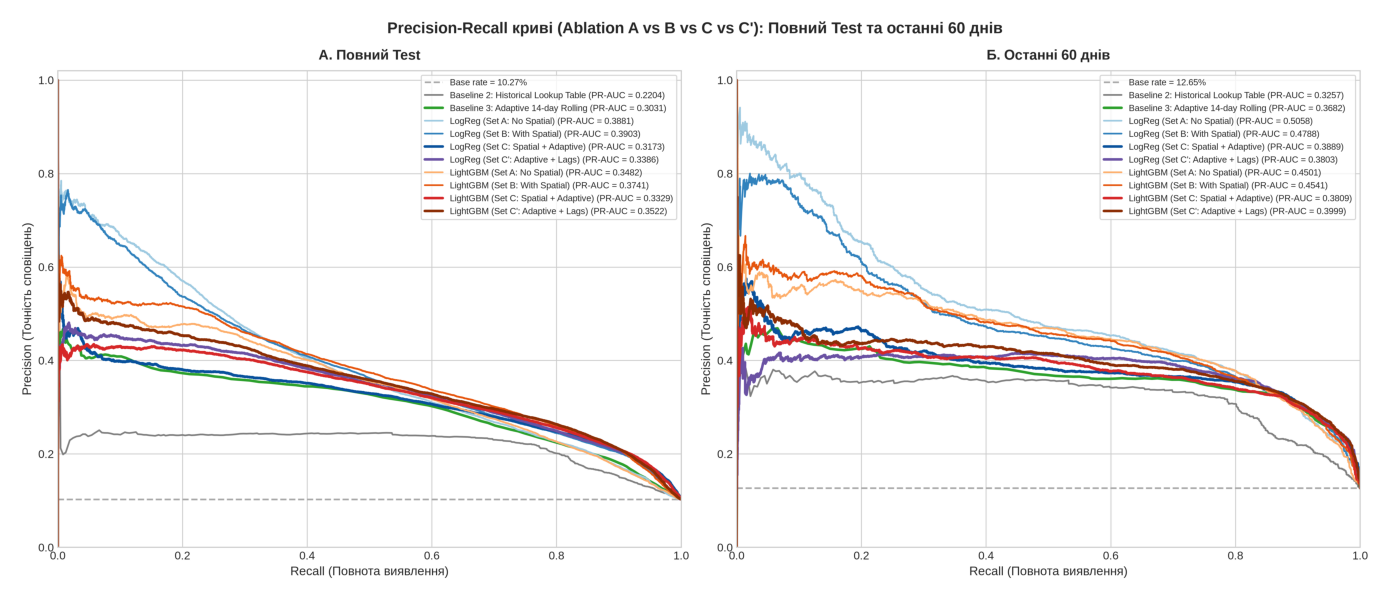

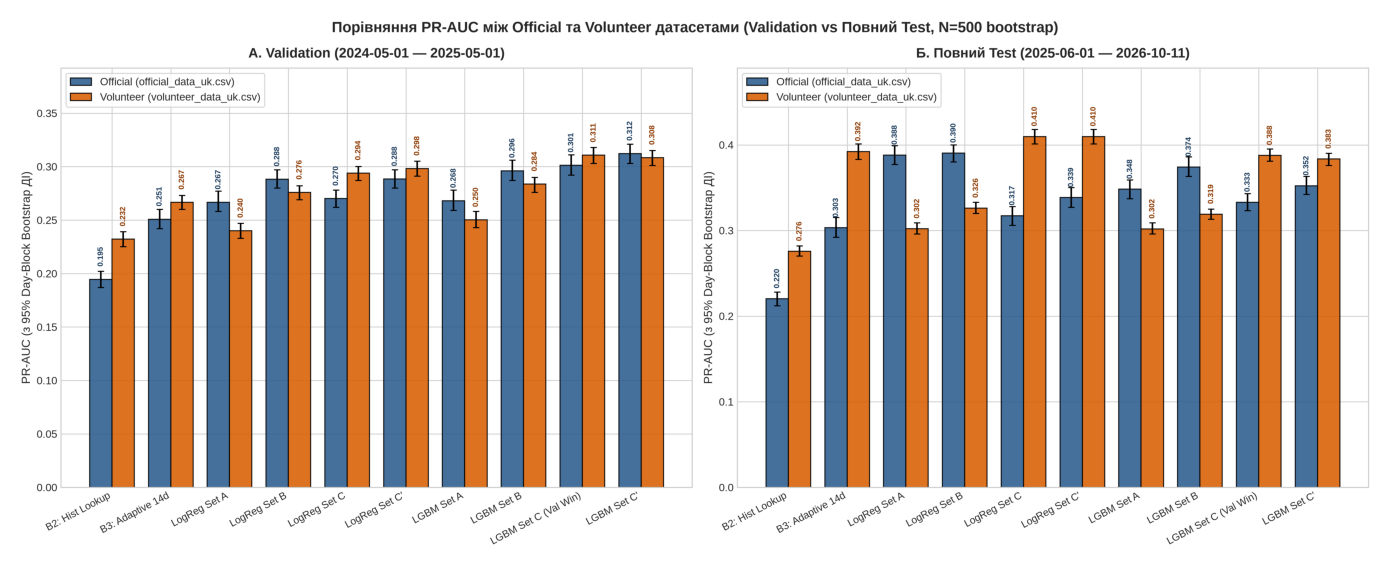

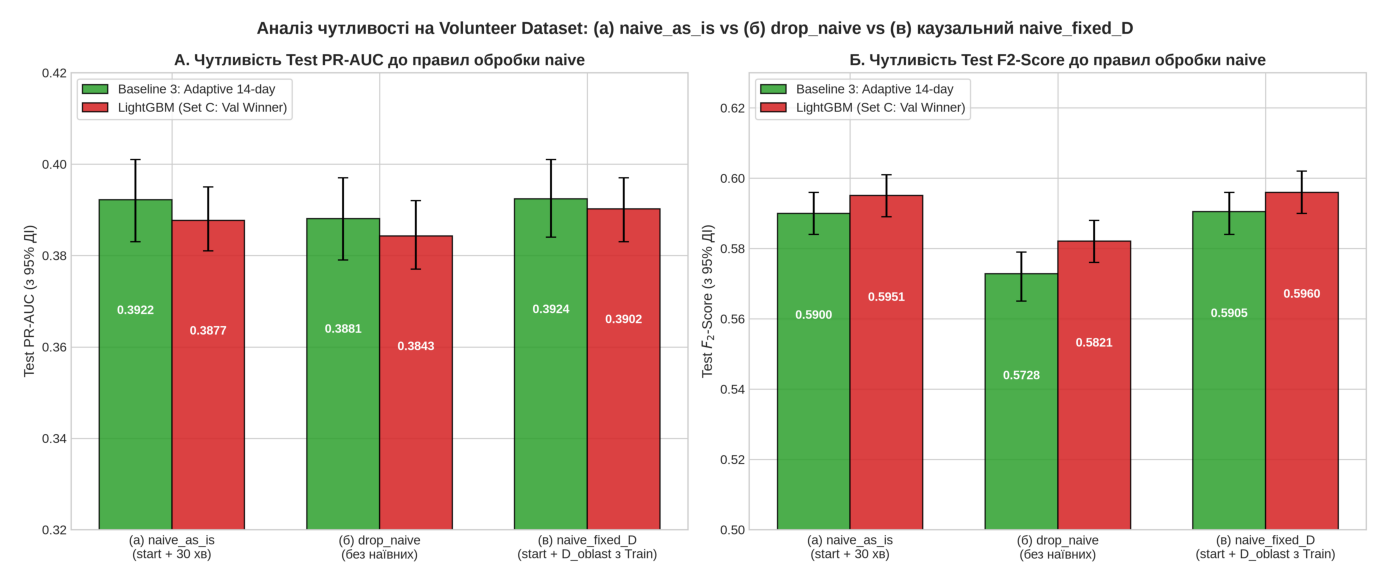

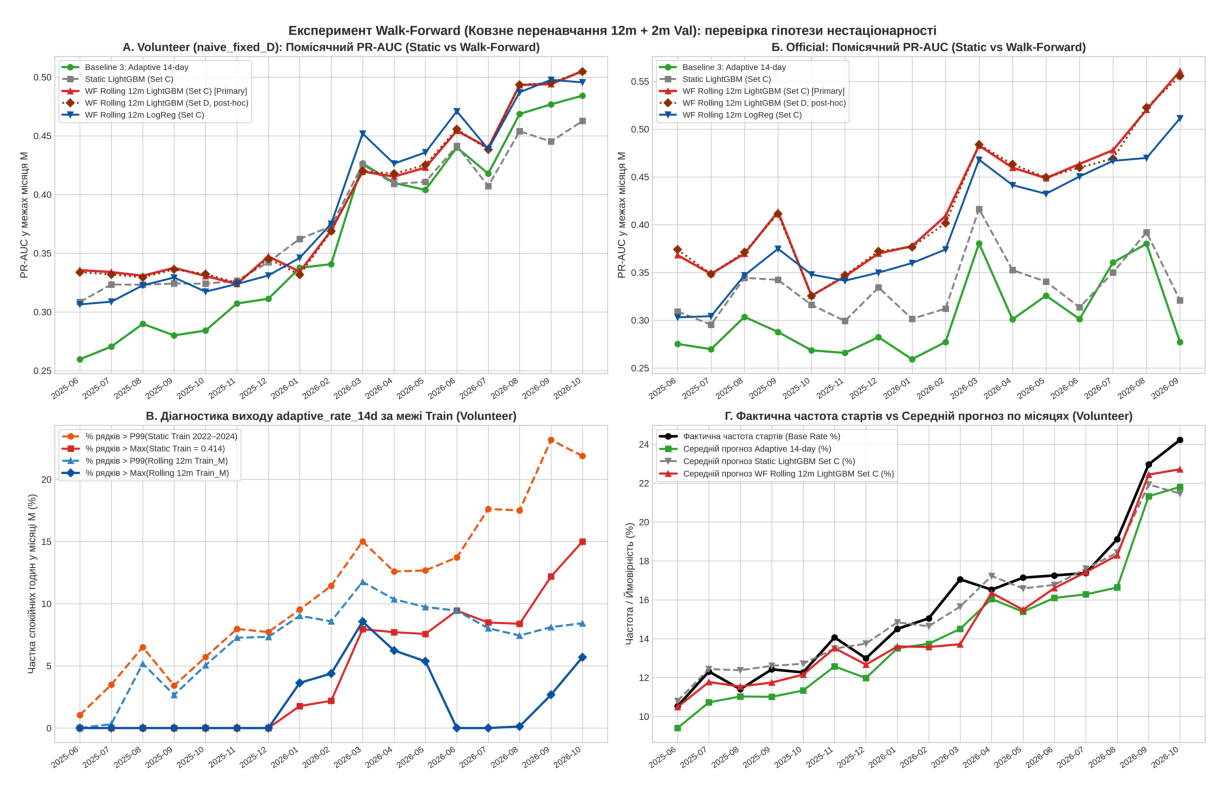

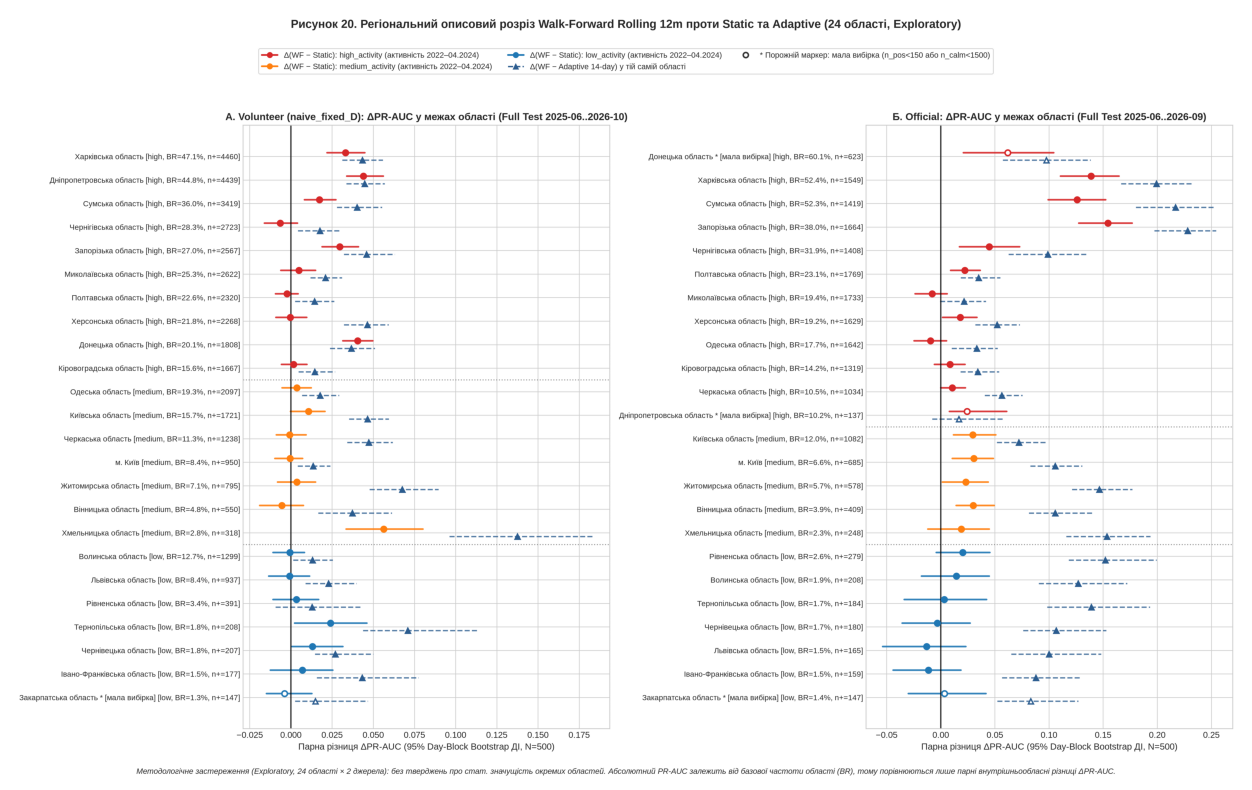

In [8]:
for fig_path in [
    off_dir / "figures" / "10_test_pr_curves_comparison.png",
    comp_dir / "figures" / "14_comparison_pr_auc_official_vs_volunteer.png",
    comp_dir / "figures" / "18_volunteer_naive_sensitivity_comparison.png",
    comp_dir / "figures" / "19_walk_forward_vs_static_comparison.png",
    comp_dir / "figures" / "20_walk_forward_regional_breakdown.png",
]:
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(mpimg.imread(fig_path))
    ax.axis("off")
    plt.tight_layout()
    plt.show()